# Baseline Model Tuning: XGBoost
Follow-up to `03_baseline_model_testing.ipynb`, which compared 5 models with their starting settings. This notebook **tunes XGBoost**: it searches for better settings (hyperparameters) and chooses the Disrupted decision threshold.

**Why XGBoost:** it is the third gradient-boosting library from the literature review. In 03 it came third in macro-F1 (0.564), behind Random Forest and LightGBM, with its starting settings. Tuning it the same way shows whether it catches up.

**How tuning is organized:** each algorithm is tuned in its own notebook (`03_2_baseline_model_tuning_lightgbm`, `03_2_baseline_model_tuning_random_forest`, `03_2_baseline_model_tuning_catboost`, `03_2_baseline_model_tuning_xgboost`, `03_2_baseline_model_tuning_logistic_regression`), and a later notebook compares them. To make the comparison fair, every tuning notebook uses the shared setup in `tuning_setup.py` (same training rows, same 5 folds, same scores, same threshold method) and saves its results in the same format to `results/tuning/<model>/`.

**The test set is still not used.** Only the final comparison notebook will score it, once.

Steps:
1. Load the training data and the shared setup
2. Score untuned XGBoost as the starting point
3. Define which settings to search, and over what ranges
4. Run a randomized search with stratified 5-fold cross-validation
5. Compare tuned vs. untuned, fold by fold
6. Choose the Disrupted threshold
7. Save the results

## 1. Load Data & Shared Setup
`tuning_setup.py` (in this folder) holds everything the tuning notebooks share:
- `load_training_data()`: the **training rows only** of `model_ready.csv`, with the target encoded as Normal = 0, Delayed = 1, Disrupted = 2 (same as 03)
- `make_folds()`: the **same 5 stratified folds as 03** (`shuffle=True, random_state=42`), so scores here can be compared directly with 03
- `score_predictions()` / `score_folds()`: the same scores as 03 (macro-F1, F1 per status, Disrupted precision/recall/PR-AUC, ROC-AUC)
- threshold helpers and `save_tuning_results()`, explained in sections 6 and 7

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict

from tuning_setup import (DISRUPTED, SEARCH_SCORING, STATUS_ORDER, THRESHOLDS, best_threshold_macro_f1,
                          choose_threshold, cross_validated_threshold, load_training_data, make_folds,
                          predict_with_threshold, save_tuning_results, score_folds, score_predictions)

train_df, X_train, y_train = load_training_data()
folds = make_folds(X_train, y_train)

print("Training rows:", len(X_train))
print(f"{X_train.shape[1]} features: {', '.join(X_train.columns)}")
print("Disrupted rows per held-out fold:", [int((y_train.iloc[valid_index] == DISRUPTED).sum()) for _, valid_index in folds])

Training rows: 25040
7 features: geopolitical_risk_score, port_congestion_index, weather_disruption_score, origin_active_event_risk, destination_active_event_risk, covid_supply_shock_active, russia_ukraine_war_active
Disrupted rows per held-out fold: [159, 160, 160, 160, 160]


## 2. Starting Point: Untuned XGBoost
The same settings as in 03 (400 trees, learning rate 0.05, depth 6).

**Class weights:** unlike the other models, XGBoost has no `class_weight` option; it only accepts per-row weights (`sample_weight`). So a small wrapper, `BalancedXGBClassifier`, computes the balanced weights (same formula as 03: `rows / (3 x rows with that status)`) **inside each fit**, from that fold's training rows. Everything else is plain XGBoost, so the search tool can use it like any other model.

`cross_val_predict` trains one model per fold and returns each row's probabilities from the model that **didn't** see it (out-of-fold probabilities, as in 03).

In [2]:
class BalancedXGBClassifier(XGBClassifier):
    """XGBoost with balanced class weights, computed from the rows it is trained on."""

    def fit(self, X, y, **kwargs):
        return super().fit(X, y, sample_weight=compute_sample_weight("balanced", y), **kwargs)


untuned_model = BalancedXGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, tree_method="hist",
                                      n_jobs=-1, random_state=42)

untuned_probabilities = cross_val_predict(untuned_model, X_train, y_train, cv=folds, method="predict_proba")
untuned_fold_scores = score_folds(y_train, untuned_probabilities, folds)

untuned_fold_scores.agg(["mean", "std"]).round(3)

,macro_f1,f1_normal,f1_delayed,f1_disrupted,disrupted_precision,disrupted_recall,disrupted_pr_auc,roc_auc_ovr
mean,0.564,0.676,0.721,0.294,0.200,0.557,0.284,0.835
std,0.006,0.006,0.006,0.019,0.014,0.040,0.026,0.001


These are exactly the XGBoost scores from 03 (macro-F1 0.564 ± 0.006, Disrupted recall 0.557, Disrupted PR-AUC 0.284). This confirms that the `BalancedXGBClassifier` wrapper gives the same class weights as the `sample_weight` approach in 03, and that the folds are the same. This is the starting point tuning has to beat.

## 3. Search Space
Like LightGBM and CatBoost, XGBoost builds trees one after another, each one fixing the mistakes of the trees before it. These are the settings that control that process, and the ranges searched:

| Setting | What it controls | Range searched | Why it matters |
|---|---|---|---|
| `n_estimators` | Number of trees | 100 to 1,500 | More trees can learn more, but too many start memorizing noise |
| `learning_rate` | How much each new tree is allowed to change the prediction | 0.005 to 0.2 (log scale) | Smaller steps usually generalize better but need more trees |
| `max_depth` | How many questions deep a tree can go | 2 to 10 | Deeper trees learn more complex patterns, and overfit more easily |
| `min_child_weight` | Smallest total row weight allowed in a leaf | 0.5 to 50 (log scale) | Large values stop the trees from fitting tiny groups of rows. With class weights, one Disrupted row counts about 10 |
| `gamma` | Smallest improvement a split must give to be kept | 0.01 to 5 (log scale) | Higher = fewer, more meaningful splits |
| `subsample` | Share of rows each tree sees | 0.5 to 1.0 | Training each tree on a random part of the rows reduces overfitting |
| `colsample_bytree` | Share of features each tree sees | 0.5 to 1.0 | Same idea for features |
| `reg_alpha`, `reg_lambda` | Penalties that keep leaf values small | 0.001 to 10 / 0.01 to 10 (log scale) | More penalty = more cautious trees |

"Log scale" means values are spread evenly in powers of 10 (e.g. as many tries between 0.005 and 0.05 as between 0.05 and 0.5), which suits settings that matter by their order of magnitude.

The fixed settings: balanced class weights (the wrapper from section 2), `tree_method="hist"` (the fast standard method), `n_jobs=1` (the search runs many models side by side instead), and a fixed `random_state`.

In [3]:
search_space = {
    "n_estimators": randint(100, 1501),
    "learning_rate": loguniform(0.005, 0.2),
    "max_depth": randint(2, 11),             # 2 to 10
    "min_child_weight": loguniform(0.5, 50),
    "gamma": loguniform(0.01, 5),
    "subsample": uniform(0.5, 0.5),          # uniform(start, width): 0.5 to 1.0
    "colsample_bytree": uniform(0.5, 0.5),
    "reg_alpha": loguniform(0.001, 10),
    "reg_lambda": loguniform(0.01, 10),
}

base_model = BalancedXGBClassifier(tree_method="hist", n_jobs=1, random_state=42)

## 4. Randomized Search
**Randomized search** tries a fixed number of random combinations from the ranges above. Trying every combination (a grid search) would take thousands of combinations; a random sample of combinations usually finds settings about as good for a small fraction of the time, because only a few settings matter a lot and random sampling tries many different values of each.

**Setup:**
- **60 combinations**, each scored with the **same 5 stratified folds** (300 models in total)
- **macro-F1 at the best threshold picks the winner** (`macro_f1_best_threshold`, see below). macro-F1 with the default rule, Disrupted PR-AUC and ROC-AUC are recorded too

**Why "at the best threshold":** every final model gets its own Disrupted threshold (section 7). If combinations were compared with the default rule (highest probability wins), the search would mostly reward settings whose default rule happens to fall near a good cut-off. For example, with class weights, models with bigger leaves call Disrupted more often under the default rule: their default-rule macro-F1 drops, even though they rank disruptions just as well and do fine once their threshold is set. So each combination is scored by the macro-F1 it reaches with its **best** threshold on each held-out fold. Picking the threshold on the same fold it is scored on is slightly optimistic, but equally so for every combination; section 7 gives the honest estimate.
- `n_jobs=-1` trains several models at the same time on all CPU cores (each model uses 1 core)

**Run time:** about 5 minutes on a 24-core machine. On a laptop with fewer cores it will take longer; lowering `n_iter` makes it faster but searches fewer combinations.

In [4]:
search = RandomizedSearchCV(
    base_model,
    param_distributions=search_space,
    n_iter=60,
    scoring=SEARCH_SCORING,
    refit="macro_f1_best_threshold",   # the best combination is chosen by macro-F1 at its best threshold
    cv=folds,
    n_jobs=-1,
    random_state=42,
    return_train_score=True,   # also keep scores on the training folds, to spot overfitting
)

start = time.perf_counter()
search.fit(X_train, y_train)
print(f"Search finished in {time.perf_counter() - start:.0f} seconds")

Search finished in 271 seconds


## 5. Search Results
The table shows the 10 best combinations by mean `macro_f1_best_threshold` across the 5 folds. `train macro_f1_best_threshold` is the same score on the rows the model **was** trained on: a big gap between train and held-out scores means the model is memorizing its training rows. `macro_f1 (default rule)` is shown for reference.

In [5]:
results_df = pd.DataFrame(search.cv_results_)
param_columns = [f"param_{name}" for name in search_space]

score_names = {
    "mean_test_macro_f1_best_threshold": "macro_f1_best_threshold",
    "std_test_macro_f1_best_threshold": "std across folds",
    "mean_train_macro_f1_best_threshold": "train macro_f1_best_threshold",
    "mean_test_macro_f1": "macro_f1 (default rule)",
    "mean_test_disrupted_pr_auc": "disrupted_pr_auc",
    "mean_test_roc_auc_ovr": "roc_auc_ovr",
    "mean_fit_time": "fit seconds",
}
search_results_df = (
    results_df[param_columns + list(score_names)]
    .rename(columns={**{f"param_{name}": name for name in search_space}, **score_names})
    .sort_values("macro_f1_best_threshold", ascending=False)
    .reset_index(drop=True)
)

search_results_df.head(10).round(3)

,n_estimators,learning_rate,max_depth,min_child_weight,gamma,subsample,colsample_bytree,reg_alpha,reg_lambda,macro_f1_best_threshold,std across folds,train macro_f1_best_threshold,macro_f1 (default rule),disrupted_pr_auc,roc_auc_ovr,fit seconds
0,587,0.026,7,13.433,2.952,0.758,0.529,5.476,0.822,0.614,0.008,0.650,0.550,0.326,0.840,7.397
1,566,0.074,6,1.026,3.681,0.667,0.687,0.003,0.239,0.613,0.006,0.689,0.565,0.313,0.842,8.885
2,915,0.026,5,7.848,1.876,0.760,0.516,0.020,0.514,0.611,0.008,0.683,0.559,0.313,0.841,11.744
3,153,0.066,4,25.800,0.057,0.542,0.594,1.317,0.844,0.611,0.007,0.641,0.542,0.327,0.838,2.060
4,1352,0.006,6,48.406,0.074,0.538,0.778,0.010,1.220,0.611,0.009,0.654,0.551,0.326,0.841,20.391
5,905,0.006,9,23.113,0.571,0.809,0.571,0.001,9.476,0.610,0.007,0.710,0.568,0.323,0.842,18.896
6,825,0.017,4,7.613,0.069,0.560,0.532,3.539,0.261,0.610,0.006,0.649,0.548,0.324,0.840,11.173
7,858,0.008,7,2.618,1.952,0.806,0.661,0.048,0.059,0.610,0.010,0.705,0.568,0.324,0.844,13.274
8,541,0.067,2,0.674,0.251,0.749,0.662,7.076,0.057,0.610,0.009,0.629,0.537,0.328,0.838,6.124
9,198,0.047,4,2.777,2.662,0.653,0.581,7.846,0.071,0.610,0.007,0.628,0.535,0.329,0.837,2.621


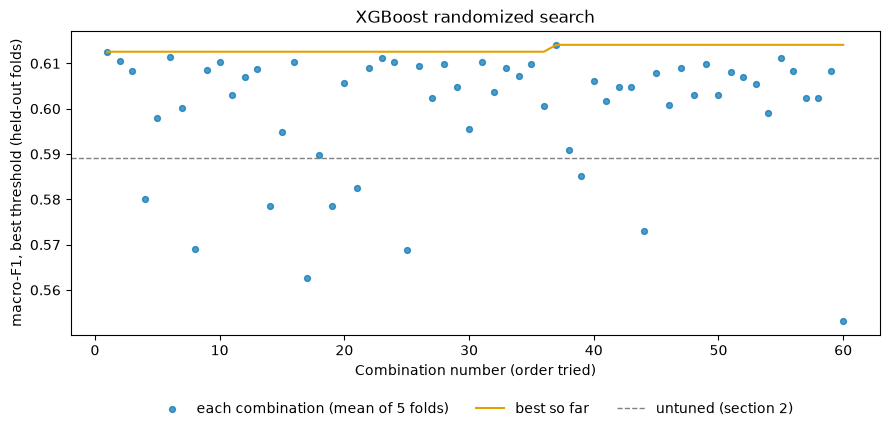

Best settings:
  colsample_bytree: 0.5291
  gamma: 2.952
  learning_rate: 0.02556
  max_depth: 7
  min_child_weight: 13.43
  n_estimators: 587
  reg_alpha: 5.476
  reg_lambda: 0.8219
  subsample: 0.7583


In [6]:
# Each combination's held-out macro-F1 (best threshold), in the order they were tried, and the best score so far
untuned_best_threshold_f1 = np.mean([best_threshold_macro_f1(y_train.iloc[valid_index], untuned_probabilities[valid_index])
                                     for _, valid_index in folds])

fig, ax = plt.subplots(figsize=(9, 4.5))
tried = results_df["mean_test_macro_f1_best_threshold"].to_numpy()
ax.scatter(np.arange(1, len(tried) + 1), tried, s=18, color="#0072B2", alpha=0.7, label="each combination (mean of 5 folds)")
ax.plot(np.arange(1, len(tried) + 1), np.maximum.accumulate(tried), color="#E69F00", label="best so far")
ax.axhline(untuned_best_threshold_f1, color="gray", ls="--", lw=1, label="untuned (section 2)")
ax.set_xlabel("Combination number (order tried)")
ax.set_ylabel("macro-F1, best threshold (held-out folds)")
ax.set_title("XGBoost randomized search")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

best_params = search.best_params_
print("Best settings:")
for name, value in best_params.items():
    print(f"  {name}: {value:.4g}" if isinstance(value, float) else f"  {name}: {value}")

### Reading the Search
- **The best combination reaches 0.614** macro-F1 at its best threshold, vs. 0.589 for the untuned model scored the same way (dashed line). 50 of the 60 combinations beat the untuned model.
- **Every top-10 combination holds the trees back in at least one way:** a large minimum leaf weight (`min_child_weight` of 7 or more), a split threshold (`gamma` around 2 or more) or a strong penalty (`reg_alpha` around 5 or more). Each tree also sees only about half to three quarters of the features. The best one: 587 trees, depth 7, learning rate 0.026, `min_child_weight` 13, `gamma` 3.0, strong `reg_alpha` (5.5).
- **Many settings score about the same.** The top 10 are all between 0.610 and 0.614, well within the fold-to-fold spread (about 0.008), so the exact "best" values shouldn't be over-interpreted.
- The top combinations also have high Disrupted PR-AUC (about 0.31-0.33), similar to tuned LightGBM and CatBoost.

## 6. Tuned vs. Untuned
Get out-of-fold probabilities for the best settings (same folds), and compare with the untuned model **fold by fold**. Because both models are scored on exactly the same rows in each fold, the fold-by-fold difference shows whether the improvement is consistent or just noise.

The main comparison gives **each model its own Disrupted threshold**, chosen on the other 4 folds (the honest method from section 7), because that is how the final model will be used. The default-rule scores are shown too.

Note: the best settings were chosen using these same 5 folds, so the tuned score is slightly optimistic (it was the luckiest of 60 tries on these folds). The final test-set score in the comparison notebook will show the real number.

In [7]:
tuned_model = search.best_estimator_
tuned_probabilities = cross_val_predict(tuned_model, X_train, y_train, cv=folds, method="predict_proba")
tuned_fold_scores = score_folds(y_train, tuned_probabilities, folds)   # default rule

# Each model with its own threshold, chosen on the other 4 folds and scored on the held-out fold
untuned_threshold_scores = cross_validated_threshold(y_train, untuned_probabilities, folds).drop(columns="threshold")
tuned_threshold_fold_scores = cross_validated_threshold(y_train, tuned_probabilities, folds)
tuned_threshold_scores = tuned_threshold_fold_scores.drop(columns="threshold")

comparison = pd.DataFrame({
    "untuned, default rule": untuned_fold_scores.mean(),
    "tuned, default rule": tuned_fold_scores.mean(),
    "untuned, own threshold": untuned_threshold_scores.mean(),
    "tuned, own threshold": tuned_threshold_scores.mean(),
    "change with thresholds (mean)": (tuned_threshold_scores - untuned_threshold_scores).mean(),
    "change (std across folds)": (tuned_threshold_scores - untuned_threshold_scores).std(),
    "folds improved (of 5)": (tuned_threshold_scores > untuned_threshold_scores).sum(),
})
comparison.round(3)

,"untuned, default rule","tuned, default rule","untuned, own threshold","tuned, own threshold",change with thresholds (mean),change (std across folds),folds improved (of 5)
macro_f1,0.564,0.550,0.587,0.606,0.019,0.009,5
f1_normal,0.676,0.687,0.676,0.687,0.011,0.003,5
f1_delayed,0.721,0.685,0.764,0.772,0.008,0.005,5
f1_disrupted,0.294,0.278,0.319,0.359,0.039,0.030,5
disrupted_precision,0.200,0.172,0.302,0.342,0.041,0.031,4
disrupted_recall,0.557,0.722,0.340,0.378,0.038,0.041,3
disrupted_pr_auc,0.284,0.326,0.284,0.326,0.042,0.019,5
roc_auc_ovr,0.835,0.840,0.835,0.840,0.005,0.001,5


### Reading the Comparison
- **With their own thresholds, tuning improves macro-F1 by about 0.019 (0.587 -> 0.606), on all 5 folds**, and Disrupted PR-AUC by about 0.042 (0.284 -> 0.326), also on all 5 folds. The tuned model really is better at recognizing disruptions, not just more or less cautious.
- With the default rule, the tuned model looks worse (0.550 vs. 0.564), because its Disrupted probabilities are higher overall, so "highest probability wins" flags too many rows (recall 0.72, precision 0.17). This is exactly why settings are compared at their own thresholds.
- Like LightGBM, the untuned XGBoost was learning its training rows too closely; holding the trees back is what helps.

## 7. Choose the Disrupted Threshold
As in 03, a row is called Disrupted when its Disrupted probability is at least a threshold; otherwise the more likely of Normal and Delayed is predicted. Thresholds from 0.05 to 0.95 in steps of 0.01 are tried.

**How the threshold is chosen:** the one with the **highest macro-F1**. This is the default until the team agrees on the cost of a missed disruption vs. a false alarm (see the recall-target table below for an alternative).

**How it is scored honestly:** a threshold chosen and scored on the same rows looks better than it really is. So, for each fold, the threshold is chosen on the **other 4 folds** and then scored on this fold, which it never saw (`cross_validated_threshold` in `tuning_setup.py`). The threshold saved for the final model is chosen on all training rows.

In [8]:
threshold_fold_scores = tuned_threshold_fold_scores   # from section 6
final_threshold = choose_threshold(y_train, tuned_probabilities)

threshold_comparison = pd.DataFrame({
    "default rule (mean)": tuned_fold_scores.mean(),
    "chosen threshold (mean)": threshold_fold_scores.drop(columns="threshold").mean(),
    "change (mean)": (threshold_fold_scores.drop(columns="threshold") - tuned_fold_scores).mean(),
    "folds improved (of 5)": (threshold_fold_scores.drop(columns="threshold") > tuned_fold_scores).sum(),
})
print("Threshold chosen in each fold (on the other 4 folds):", threshold_fold_scores["threshold"].tolist())
print("Final threshold (chosen on all training rows):", final_threshold)
threshold_comparison.round(3)

Threshold chosen in each fold (on the other 4 folds): [0.78, 0.8, 0.79, 0.8, 0.81]
Final threshold (chosen on all training rows): 0.8


,default rule (mean),chosen threshold (mean),change (mean),folds improved (of 5)
macro_f1,0.550,0.606,0.056,5
f1_normal,0.687,0.687,-0.000,0
f1_delayed,0.685,0.772,0.087,5
f1_disrupted,0.278,0.359,0.081,5
disrupted_precision,0.172,0.342,0.170,5
disrupted_recall,0.722,0.378,-0.344,0
disrupted_pr_auc,0.326,0.326,0.000,0
roc_auc_ovr,0.840,0.840,0.000,0


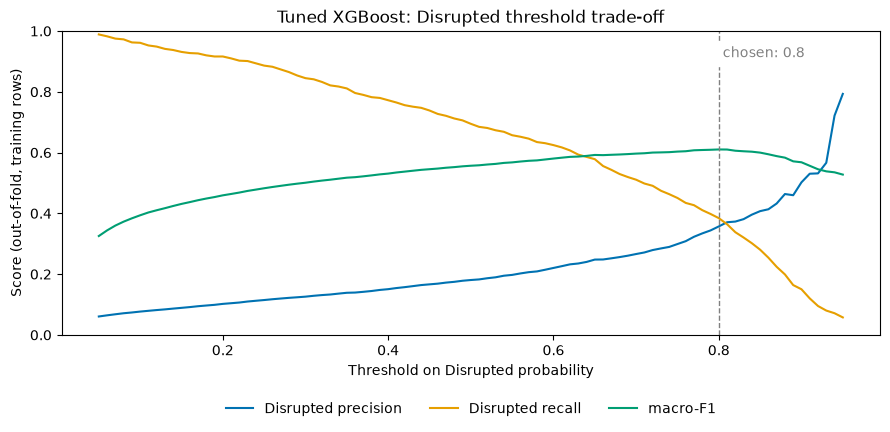

In [9]:
# The full trade-off for the tuned model (out-of-fold, all training rows)
trade_off = pd.DataFrame([
    {"threshold": t, **score_predictions(y_train, tuned_probabilities, t),
     "rows flagged Disrupted": int((predict_with_threshold(tuned_probabilities, t) == DISRUPTED).sum())}
    for t in THRESHOLDS
]).set_index("threshold")

fig, ax = plt.subplots(figsize=(9, 4.5))
for column, color, label in [("disrupted_precision", "#0072B2", "Disrupted precision"),
                             ("disrupted_recall", "#E69F00", "Disrupted recall"),
                             ("macro_f1", "#009E73", "macro-F1")]:
    ax.plot(trade_off.index, trade_off[column], color=color, label=label)
ax.axvline(final_threshold, color="gray", ls="--", lw=1)
ax.text(final_threshold, 0.95, f" chosen: {final_threshold}", color="gray", va="top", backgroundcolor="white")
ax.set_xlabel("Threshold on Disrupted probability")
ax.set_ylabel("Score (out-of-fold, training rows)")
ax.set_ylim(0, 1)
ax.set_title("Tuned XGBoost: Disrupted threshold trade-off")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### Alternative: a Recall Target
If the team decides that catching disruptions matters more than avoiding false alarms, a threshold can instead be chosen to reach a **recall target**: the highest threshold that still catches at least that share of real disruptions. The table shows what each target would cost in precision and false alarms.

In [10]:
recall_target_rows = []
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    meets_target = trade_off[trade_off["disrupted_recall"] >= target]
    if meets_target.empty:
        # Even the lowest threshold tried doesn't catch this share of disruptions
        recall_target_rows.append({"recall target": target, "threshold": "not reachable"})
        continue
    threshold = meets_target.index.max()
    row = trade_off.loc[threshold]
    caught = row["disrupted_recall"] * (y_train == DISRUPTED).sum()
    recall_target_rows.append({
        "recall target": target,
        "threshold": threshold,
        "disrupted_recall": row["disrupted_recall"],
        "disrupted_precision": row["disrupted_precision"],
        "macro_f1": row["macro_f1"],
        "false alarms per disruption caught": (row["rows flagged Disrupted"] - caught) / caught,
    })

pd.DataFrame(recall_target_rows).set_index("recall target").round(3)

,threshold,disrupted_recall,disrupted_precision,macro_f1,false alarms per disruption caught
recall target,,,,,
0.5,0.70,0.511,0.266,0.597,2.757
0.6,0.62,0.607,0.232,0.586,3.307
0.7,0.49,0.706,0.178,0.555,4.612
0.8,0.35,0.811,0.139,0.517,6.215
0.9,0.23,0.901,0.110,0.474,8.103


### Reading the Threshold Results
- **The chosen threshold improves macro-F1 by about 0.056 over the default rule, on all 5 folds.** The thresholds chosen in each fold are very stable (0.78 to 0.81), and the final threshold is **0.80**.
- Why so high: the class weights make the model's Disrupted probabilities much larger than the real chance of a disruption. A threshold around 0.8 undoes that push.
- The trade-off: Disrupted precision doubles (0.17 -> 0.34) but recall falls (0.72 -> 0.38).
- **Recall targets** (from the table): catching 50% of disruptions costs about 2.8 false alarms per disruption caught (threshold 0.70), 70% costs about 4.6 (0.49), and 90% about 8.1 (0.23).

## 8. Save the Results
Saved to `results/tuning/xgboost/` in the shared format, so the comparison notebook can load every algorithm the same way:
- `best_params.json`: the best settings and the chosen Disrupted threshold
- `cv_fold_scores.csv`: the tuned model's scores on each fold, with the chosen threshold (from section 7, chosen on the other folds)
- `out_of_fold_probabilities.csv`: each training row's out-of-fold probabilities, with `date`, `route_id` and the true status
- `search_results.csv`: every combination tried in the search, best first

In [11]:
folder = save_tuning_results(
    model_name="XGBoost",
    best_params=best_params,
    fold_scores_df=threshold_fold_scores,
    out_of_fold_probabilities=tuned_probabilities,
    train_df=train_df,
    threshold=final_threshold,
    search_results_df=search_results_df,
)
print("Saved to", folder)

Saved to ../results/tuning\xgboost


## 9. Summary
**Setup:** randomized search over 9 XGBoost settings (60 combinations), stratified 5-fold cross-validation on the training rows (same folds as 03), balanced class weights (computed inside each fit). Settings chosen by **macro-F1 at their best Disrupted threshold**. The test set was not used.

**Results (mean over the 5 folds; each model with its own threshold, chosen on the other 4 folds)**

| | macro-F1 | Disrupted F1 | Disrupted precision | Disrupted recall | Disrupted PR-AUC |
|---|---|---|---|---|---|
| Untuned (03 settings) | 0.587 | 0.319 | 0.302 | 0.340 | 0.284 |
| **Tuned** (threshold 0.80) | **0.606** | **0.359** | 0.342 | 0.378 | **0.326** |

**What we learned**
1. Tuning helps XGBoost clearly: +0.019 macro-F1 and +0.042 Disrupted PR-AUC, better on all 5 folds.
2. The best settings hold the trees back (minimum leaf weight, split threshold, feature sampling, penalties): the untuned model was learning its training rows too closely.
3. A high threshold (about 0.8) is needed to undo the push the class weights give to Disrupted.
4. Tuned XGBoost ends up close to tuned CatBoost and LightGBM (all within about 0.01 macro-F1).

**Saved:** `results/tuning/xgboost/` (best settings, threshold 0.80, fold scores, out-of-fold probabilities, all search results).

**Next steps**
- Compare all five tuned models (LightGBM, Random Forest, CatBoost, XGBoost, Logistic Regression) in one notebook, using the saved results in `results/tuning/`.
- Agree as a team on what the final model should optimize: macro-F1 (current default), or a recall target. The recall-target table shows what each target costs in false alarms.
- Score the chosen model **once** on the test set, and also report the score for test rows from 2026-06-07 onward.